In [8]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Load data
data = fetch_california_housing()
X, y = data.data, data.target

# Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Scale
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print("Train:", X_train.shape)
print("Test:", X_test.shape)

Train: (16512, 8)
Test: (4128, 8)


In [9]:
def build_model(activation='relu', loss='mse'):
    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(8,)),
        tf.keras.layers.Dense(64, activation=activation),
        tf.keras.layers.Dense(32, activation=activation),
        tf.keras.layers.Dense(1)
    ])
    model.compile(optimizer='adam', loss=loss, metrics=['mae'])
    return model

model = build_model('relu', 'mse')

history = model.fit(
    X_train, y_train,
    epochs=50,
    batch_size=32,
    validation_split=0.2,
    verbose=0
)

print("Training completed!")

Training completed!


In [10]:
y_pred = model.predict(X_test, verbose=0).flatten()

mse = mean_squared_error(y_test, y_pred)

print("MSE :", round(mse, 4))
print("RMSE:", round(np.sqrt(mse), 4))
print("MAE :", round(mean_absolute_error(y_test, y_pred), 4))
print("R²  :", round(r2_score(y_test, y_pred), 4))

MSE : 0.2917
RMSE: 0.5401
MAE : 0.3669
R²  : 0.7774


In [11]:
experiments = [
    ('ReLU + MSE', 'relu', 'mse'),
    ('Tanh + MSE', 'tanh', 'mse'),
    ('Sigmoid + MSE', 'sigmoid', 'mse'),
    ('ReLU + MAE', 'relu', 'mae'),
    ('ReLU + Huber', 'relu', 'huber')
]

results = []

for name, activation, loss in experiments:
    m = build_model(activation, loss)
    h = m.fit(X_train, y_train, epochs=50,
              batch_size=32, validation_split=0.2, verbose=0)

    pred = m.predict(X_test, verbose=0).flatten()
    results.append([
        name,
        mean_squared_error(y_test, pred),
        mean_absolute_error(y_test, pred),
        r2_score(y_test, pred)
    ])

print("Experiment Results")
for r in results:
    print(f"{r[0]:15} MSE={r[1]:.4f}  MAE={r[2]:.4f}  R²={r[3]:.4f}")

Experiment Results
ReLU + MSE      MSE=0.2839  MAE=0.3655  R²=0.7833
Tanh + MSE      MSE=0.2799  MAE=0.3570  R²=0.7864
Sigmoid + MSE   MSE=0.3444  MAE=0.4161  R²=0.7371
ReLU + MAE      MSE=0.2874  MAE=0.3498  R²=0.7807
ReLU + Huber    MSE=0.2836  MAE=0.3567  R²=0.7836


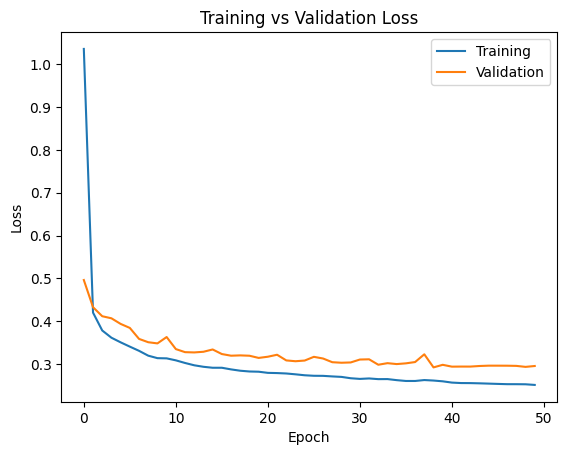

In [12]:
plt.plot(history.history['loss'], label='Training')
plt.plot(history.history['val_loss'], label='Validation')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training vs Validation Loss')
plt.legend()
plt.show()

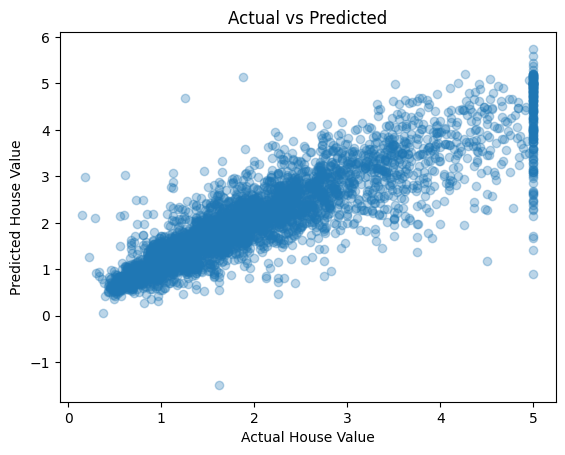

In [13]:
plt.scatter(y_test, y_pred, alpha=0.3)
plt.xlabel('Actual House Value')
plt.ylabel('Predicted House Value')
plt.title('Actual vs Predicted')
plt.show()